# ConvNeXt-Tiny Transfer Learning Baseline

ConvNeXt-Tiny is evaluated as a modern convolutional architecture following the ResNet50 and EfficientNetV2-S baselines. The experiment retains the fixed split and controlled transfer-learning protocol established in the preceding notebooks, while using preprocessing appropriate for the model's pretrained weights.

Architecture comparison is based only on validation metrics. The test subset remains frozen and is used here only for structural manifest validation and counting.


## 1. Imports and Reproducibility

All random generators are seeded with the project seed. Deterministic PyTorch behavior is requested where available; unsupported deterministic operations emit warnings rather than stopping the experiment.


In [1]:
from pathlib import Path
import os
import random
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)
import torch
import torchvision
from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import ConvNeXt_Tiny_Weights, convnext_tiny
from tqdm.auto import tqdm

RANDOM_SEED = 42


def set_reproducible_seed(seed: int) -> None:
    """Configure deterministic random states for Python, NumPy, and PyTorch."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


set_reproducible_seed(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CUDA_AVAILABLE = torch.cuda.is_available()
GPU_NAME = torch.cuda.get_device_name(0) if CUDA_AVAILABLE else "Not available"
GPU_MEMORY_GB = (
    torch.cuda.get_device_properties(0).total_memory / 1024**3
    if CUDA_AVAILABLE
    else 0.0
)

print(f"PyTorch version: {torch.__version__}")
print(f"torchvision version: {torchvision.__version__}")
print(f"CUDA available: {CUDA_AVAILABLE}")
print(f"CUDA runtime: {torch.version.cuda}")
print(f"Selected device: {DEVICE}")
print(f"GPU name: {GPU_NAME}")
print(
    f"Total GPU memory: {GPU_MEMORY_GB:.2f} GB"
    if CUDA_AVAILABLE
    else "Total GPU memory: Not available"
)


PyTorch version: 2.13.0+cu132
torchvision version: 0.28.0+cu132
CUDA available: True
CUDA runtime: 13.2
Selected device: cuda
GPU name: NVIDIA GeForce RTX 3060 Laptop GPU
Total GPU memory: 6.00 GB


## 2. Project Paths

The project root is resolved from the current working directory rather than assumed from the notebook location. Existing processed manifests are required; the split is never recreated or modified.


In [2]:
RAW_RELATIVE_PATH = Path("data/raw/skin-diseases-image-dataset/IMG_CLASSES")


def find_project_root(start: Path) -> Path:
    """Find the nearest parent containing the raw dataset and processed manifests."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (
            (candidate / RAW_RELATIVE_PATH).is_dir()
            and (candidate / "data" / "processed").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root containing the raw dataset and "
        "data/processed."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DATA_DIR = PROJECT_ROOT / RAW_RELATIVE_PATH
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
PREDICTIONS_DIR = REPORTS_DIR / "predictions"
MODELS_DIR = PROJECT_ROOT / "models"
TORCH_CACHE_DIR = MODELS_DIR / "torch_cache"

for directory in [
    REPORTS_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR,
    MODELS_DIR,
    TORCH_CACHE_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

torch.hub.set_dir(str(TORCH_CACHE_DIR))

MANIFEST_PATHS = {
    "train": PROCESSED_DIR / "train.csv",
    "validation": PROCESSED_DIR / "validation.csv",
    "test": PROCESSED_DIR / "test.csv",
}
missing_manifests = [path for path in MANIFEST_PATHS.values() if not path.is_file()]
if missing_manifests:
    missing_text = "\n".join(f"  - {path}" for path in missing_manifests)
    raise FileNotFoundError(
        "Processed manifests are missing. Execute "
        "notebooks/02_dataset_cleaning_and_split.ipynb first. Missing files:\n"
        f"{missing_text}"
    )

CHECKPOINT_PATH = MODELS_DIR / "convnext_tiny_baseline_best.pth"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw dataset: {RAW_DATA_DIR}")
print(f"Model checkpoint: {CHECKPOINT_PATH}")


Project root: C:\Projekt konferencyjny Turcja\skin-disease-classification
Raw dataset: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\raw\skin-diseases-image-dataset\IMG_CLASSES
Model checkpoint: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\convnext_tiny_baseline_best.pth


## 3. Load and Validate Manifests

All three manifests are checked for their required schema, split labels, class identifiers, group assignments, file references, and path separation. The test table is not converted into a dataset or loader and no test inference is performed.


In [3]:
manifests = {
    split_name: pd.read_csv(path)
    for split_name, path in MANIFEST_PATHS.items()
}
REQUIRED_COLUMNS = {"relative_path", "class_name", "class_id", "group_id"}

for split_name, manifest in manifests.items():
    missing_columns = REQUIRED_COLUMNS - set(manifest.columns)
    if missing_columns:
        raise ValueError(
            f"{MANIFEST_PATHS[split_name].name} is missing columns: "
            f"{sorted(missing_columns)}"
        )
    if manifest[list(REQUIRED_COLUMNS)].isna().any().any():
        raise ValueError(
            f"Required values are missing in {MANIFEST_PATHS[split_name].name}."
        )
    if manifest["relative_path"].duplicated().any():
        raise ValueError(f"Duplicate paths exist within the {split_name} manifest.")
    if "split" in manifest.columns and not manifest["split"].eq(split_name).all():
        raise ValueError(
            f"The split column is inconsistent in "
            f"{MANIFEST_PATHS[split_name].name}."
        )
    numeric_class_ids = pd.to_numeric(manifest["class_id"], errors="coerce")
    if numeric_class_ids.isna().any() or not np.equal(
        numeric_class_ids, numeric_class_ids.astype(int)
    ).all():
        raise ValueError(f"Non-integer class IDs exist in the {split_name} manifest.")

all_paths = pd.concat(
    [
        manifest[["relative_path"]].assign(source_split=split_name)
        for split_name, manifest in manifests.items()
    ],
    ignore_index=True,
)
if all_paths["relative_path"].duplicated().any():
    duplicated_paths = all_paths.loc[
        all_paths["relative_path"].duplicated(keep=False), "relative_path"
    ]
    raise ValueError(
        f"{duplicated_paths.nunique():,} image path(s) occur in more than one split."
    )

all_groups = pd.concat(
    [
        manifest[["group_id"]].assign(source_split=split_name)
        for split_name, manifest in manifests.items()
    ],
    ignore_index=True,
)
group_split_counts = all_groups.groupby("group_id")["source_split"].nunique()
if (group_split_counts > 1).any():
    raise ValueError(
        f"{int((group_split_counts > 1).sum()):,} group ID(s) occur across splits."
    )

missing_images = [
    relative_path
    for relative_path in all_paths["relative_path"]
    if not (PROJECT_ROOT / relative_path).is_file()
]
if missing_images:
    raise FileNotFoundError(
        f"{len(missing_images):,} manifest image paths do not exist on disk."
    )

split_summary = pd.DataFrame(
    {
        "split": list(manifests),
        "images": [len(manifests[name]) for name in manifests],
    }
)
split_summary["percentage"] = (
    100 * split_summary["images"] / split_summary["images"].sum()
)
display(split_summary)

class_distribution = pd.concat(
    [
        manifest.groupby(["class_id", "class_name"])
        .size()
        .rename("images")
        .reset_index()
        .assign(split=split_name)
        for split_name, manifest in manifests.items()
    ],
    ignore_index=True,
)
display(class_distribution.sort_values(["class_id", "split"]))

print(f"Training images: {len(manifests['train']):,}")
print(f"Validation images: {len(manifests['validation']):,}")
print(f"Frozen test images (structural validation only): {len(manifests['test']):,}")
print(f"Unique paths across all splits: {all_paths['relative_path'].nunique():,}")
print(f"Unique group IDs across all splits: {all_groups['group_id'].nunique():,}")


,split,images,percentage
0,train,18491,70.009844
1,validation,3961,14.996971
2,test,3960,14.993185


,class_id,class_name,images,split
20,0,Eczema,230,test
0,0,Eczema,1068,train
10,0,Eczema,228,validation
21,1,Melanoma,470,test
1,1,Melanoma,2195,train
11,1,Melanoma,471,validation
22,2,Atopic Dermatitis,174,test
2,2,Atopic Dermatitis,804,train
12,2,Atopic Dermatitis,171,validation
23,3,Basal Cell Carcinoma (BCC),496,test


Training images: 18,491
Validation images: 3,961
Frozen test images (structural validation only): 3,960
Unique paths across all splits: 26,412
Unique group IDs across all splits: 26,293


## 4. Class Mapping

Labels are taken directly from the manifests. Directory order and folder names do not determine class identifiers.


In [4]:
mapping_frames = []
for split_name, manifest in manifests.items():
    split_mapping = manifest[["class_id", "class_name"]].drop_duplicates().copy()
    split_mapping["class_id"] = split_mapping["class_id"].astype(int)
    if (
        split_mapping["class_id"].duplicated().any()
        or split_mapping["class_name"].duplicated().any()
    ):
        raise ValueError(
            f"The class mapping is not one-to-one in the {split_name} manifest."
        )
    mapping_frames.append(split_mapping.assign(split=split_name))

mapping_check = pd.concat(mapping_frames, ignore_index=True)
class_mapping_table = (
    mapping_check[["class_id", "class_name"]]
    .drop_duplicates()
    .sort_values("class_id", ignore_index=True)
)
if mapping_check.groupby("split").size().nunique() != 1:
    raise ValueError("The manifests do not contain the same number of classes.")
if class_mapping_table["class_id"].tolist() != list(range(len(class_mapping_table))):
    raise ValueError("Class IDs are not contiguous from zero.")
for split_name, split_mapping in mapping_check.groupby("split"):
    observed = (
        split_mapping[["class_id", "class_name"]]
        .sort_values("class_id")
        .reset_index(drop=True)
    )
    if not observed.equals(class_mapping_table):
        raise ValueError(f"Class mapping differs in the {split_name} manifest.")

CLASS_ID_TO_NAME = dict(
    zip(class_mapping_table["class_id"], class_mapping_table["class_name"])
)
NUM_CLASSES = len(CLASS_ID_TO_NAME)
display(class_mapping_table)
print(f"Number of classes: {NUM_CLASSES}")


,class_id,class_name
0,0,Eczema
1,1,Melanoma
2,2,Atopic Dermatitis
3,3,Basal Cell Carcinoma (BCC)
4,4,Melanocytic Nevi (NV)
5,5,Benign Keratosis-like Lesions (BKL)
6,6,Psoriasis / Lichen Planus / Related Diseases
7,7,Seborrheic Keratoses / Other Benign Tumors
8,8,Tinea / Ringworm / Candidiasis / Other Fungal ...
9,9,Warts / Molluscum / Other Viral Infections


Number of classes: 10


## 5. ConvNeXt-Tiny Pretrained Input Processing

The standard crop resolution, interpolation, and normalization are read from the default torchvision ConvNeXt-Tiny weights. Consequently, each architecture baseline uses the input pipeline appropriate for its pretrained weights. This is a comparison of practical pretrained pipelines rather than a pure architecture-only ablation.

Training augmentation remains moderate: constrained random cropping, horizontal flipping, small rotations, and mild color jitter. Validation preprocessing is deterministic and exactly follows the pretrained weight transform.


In [5]:
PRETRAINED_WEIGHTS = ConvNeXt_Tiny_Weights.DEFAULT
validation_transform = PRETRAINED_WEIGHTS.transforms()

crop_size = tuple(validation_transform.crop_size)
if len(crop_size) == 1:
    IMAGE_SIZE = int(crop_size[0])
elif len(crop_size) == 2 and crop_size[0] == crop_size[1]:
    IMAGE_SIZE = int(crop_size[0])
else:
    raise ValueError(f"Unexpected pretrained crop size: {crop_size}")

IMAGENET_MEAN = list(validation_transform.mean)
IMAGENET_STD = list(validation_transform.std)

train_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.80, 1.00),
            ratio=(0.90, 1.10),
            interpolation=validation_transform.interpolation,
            antialias=True,
        ),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(
            degrees=10,
            interpolation=validation_transform.interpolation,
        ),
        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.10,
            hue=0.02,
        ),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

print(f"Pretrained weights: {PRETRAINED_WEIGHTS.name}")
print(f"Selected image size: {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Validation resize size: {validation_transform.resize_size}")
print(f"Normalization mean: {IMAGENET_MEAN}")
print(f"Normalization standard deviation: {IMAGENET_STD}")


Pretrained weights: IMAGENET1K_V1
Selected image size: 224 x 224
Validation resize size: [236]
Normalization mean: [0.485, 0.456, 0.406]
Normalization standard deviation: [0.229, 0.224, 0.225]


## 6. Dataset and DataLoaders

Images are opened from each manifest's `relative_path`, corrected for EXIF orientation, converted to RGB, and transformed in memory. The test manifest is deliberately excluded from dataset and loader construction.

A batch size of 16 is a conservative starting point for a GPU with approximately 6 GB of memory at the standard ConvNeXt-Tiny resolution. If CUDA memory is insufficient, stop the run, set `BATCH_SIZE = 8`, restart the kernel, and execute the notebook again from the beginning. The batch size is never changed silently.


In [6]:
class SkinDiseaseDataset(Dataset):
    """Load images and labels directly from a processed manifest."""

    def __init__(self, manifest: pd.DataFrame, project_root: Path, transform=None):
        self.manifest = manifest.reset_index(drop=True).copy()
        self.project_root = project_root
        self.transform = transform

    def __len__(self) -> int:
        return len(self.manifest)

    def __getitem__(self, index: int):
        row = self.manifest.iloc[index]
        image_path = self.project_root / row["relative_path"]
        with Image.open(image_path) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            if self.transform is not None:
                image = self.transform(image)
        return image, int(row["class_id"]), row["relative_path"]


train_dataset = SkinDiseaseDataset(
    manifests["train"], PROJECT_ROOT, transform=train_transform
)
validation_dataset = SkinDiseaseDataset(
    manifests["validation"], PROJECT_ROOT, transform=validation_transform
)

BATCH_SIZE = 16
NUM_WORKERS = 0  # Reliable for Windows and interactive Jupyter execution.
PIN_MEMORY = CUDA_AVAILABLE

train_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    generator=train_generator,
    persistent_workers=NUM_WORKERS > 0,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=NUM_WORKERS > 0,
)

print(f"Training batches: {len(train_loader):,}")
print(f"Validation batches: {len(validation_loader):,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"DataLoader workers: {NUM_WORKERS}")
print(f"Pinned memory: {PIN_MEMORY}")


Training batches: 1,156
Validation batches: 248
Batch size: 16
DataLoader workers: 0
Pinned memory: True


## 7. Data Sanity Check

A small augmented training batch is converted back to display space. This check is limited to verifying that the preprocessing preserves recognizable image content; it is not a medical interpretation of the samples.


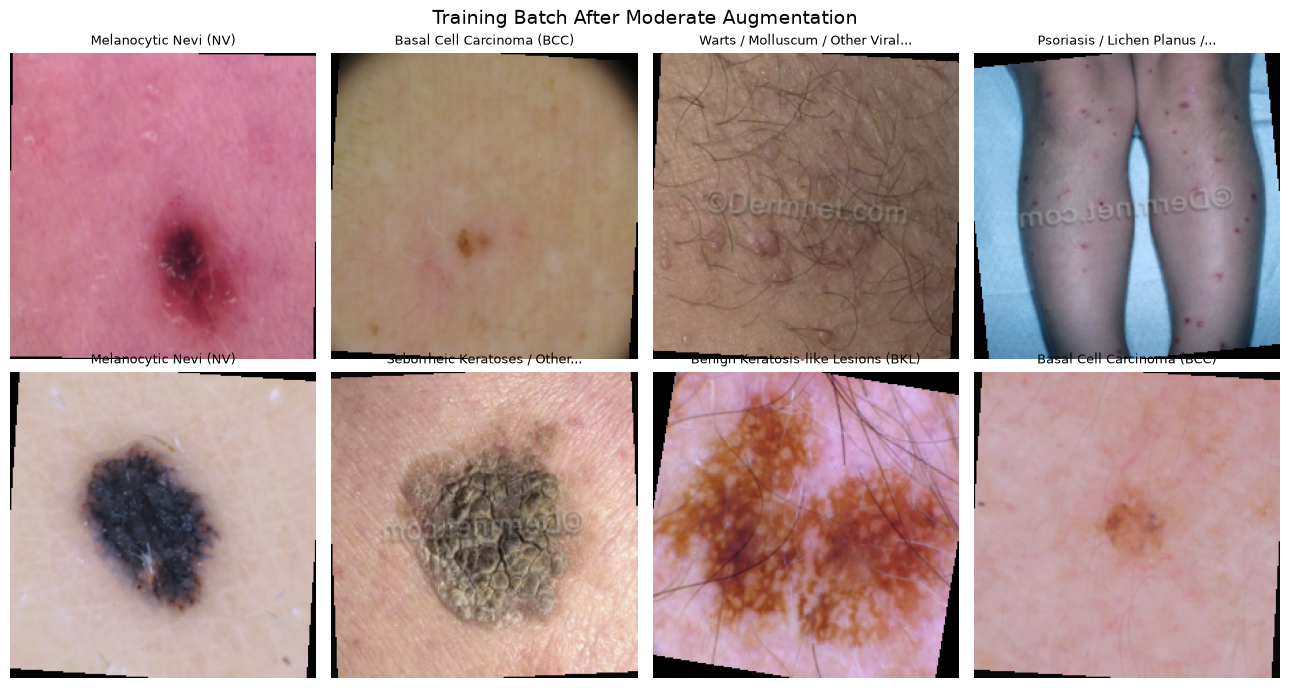

In [7]:
sample_images, sample_labels, _ = next(iter(train_loader))
train_generator.manual_seed(RANDOM_SEED)

mean_tensor = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(IMAGENET_STD).view(3, 1, 1)
display_count = min(8, len(sample_images))

fig, axes = plt.subplots(2, 4, figsize=(13, 7), squeeze=False)
for axis, image_tensor, label in zip(
    axes.flat, sample_images[:display_count], sample_labels[:display_count]
):
    image_for_display = (image_tensor.cpu() * std_tensor + mean_tensor).clamp(0, 1)
    axis.imshow(image_for_display.permute(1, 2, 0).numpy())
    axis.set_title(
        textwrap.shorten(
            CLASS_ID_TO_NAME[int(label)], width=35, placeholder="..."
        ),
        fontsize=9,
    )
    axis.axis("off")
for axis in axes.flat[display_count:]:
    axis.axis("off")
fig.suptitle("Training Batch After Moderate Augmentation", fontsize=14)
fig.tight_layout()
plt.show()


## 8. ConvNeXt-Tiny Model and Training Configuration

The default pretrained ConvNeXt-Tiny classifier is replaced with a linear layer matching the manifest-derived class count. The loss is unweighted cross-entropy. No class weighting, resampling, focal loss, MixUp, or CutMix is used in this architecture baseline.


In [8]:
model = convnext_tiny(weights=PRETRAINED_WEIGHTS)
classifier_input_features = model.classifier[-1].in_features
model.classifier[-1] = nn.Linear(classifier_input_features, NUM_CLASSES)
model = model.to(DEVICE)

total_parameters = sum(parameter.numel() for parameter in model.parameters())
initial_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)

WARMUP_EPOCHS = 3
FINE_TUNE_MAX_EPOCHS = 18
WARMUP_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 5
CHECKPOINT_CRITERION = "validation_macro_f1"

TRAINING_CONFIGURATION = {
    "random_seed": RANDOM_SEED,
    "architecture": "ConvNeXt-Tiny",
    "pretrained_weights": PRETRAINED_WEIGHTS.name,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "optimizer": "AdamW",
    "loss": "CrossEntropyLoss (unweighted)",
    "warmup_learning_rate": WARMUP_LEARNING_RATE,
    "fine_tune_learning_rate": FINE_TUNE_LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "warmup_epochs": WARMUP_EPOCHS,
    "fine_tune_max_epochs": FINE_TUNE_MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "checkpoint_criterion": CHECKPOINT_CRITERION,
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "cuda_version": torch.version.cuda,
    "gpu_name": GPU_NAME,
}

print(model)
print(f"Architecture: {TRAINING_CONFIGURATION['architecture']}")
print(f"Pretrained weights: {PRETRAINED_WEIGHTS.name}")
print(f"Total parameters: {total_parameters:,}")
print(f"Initially trainable parameters: {initial_trainable_parameters:,}")
print(f"Output classes: {NUM_CLASSES}")
print(f"Image size: {IMAGE_SIZE} x {IMAGE_SIZE}")


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to C:\Projekt konferencyjny Turcja\skin-disease-classification\models\torch_cache\checkpoints\convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:23<00:00, 4.91MB/s] 


ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True, bias=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
          (3): Linear(in_features=96, out_features=384, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=384, out_features=96, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True, bias=True)
 

## 9. Training and Validation Functions

Loss is accumulated with sample weighting. Validation uses inference mode and returns the prediction probabilities needed for later confidence analysis. Automatic mixed precision is enabled only on CUDA. Every completed epoch is written to the standardized history file.


In [9]:
criterion = nn.CrossEntropyLoss()
AMP_ENABLED = DEVICE.type == "cuda"
HISTORY_PATH = REPORTS_DIR / "05_convnext_tiny_training_history.csv"


def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device,
    freeze_backbone: bool,
):
    """Train for one epoch and return sample-weighted loss and accuracy."""
    model.train()
    if freeze_backbone:
        # Disable stochastic feature transformations while the backbone is frozen.
        model.features.eval()

    running_loss = 0.0
    correct_predictions = 0
    sample_count = 0

    progress = tqdm(loader, desc="Training", unit="batch", leave=False)
    for images, labels, _ in progress:
        try:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        except torch.OutOfMemoryError as error:
            raise RuntimeError(
                "CUDA ran out of memory. Stop this run, set BATCH_SIZE to 8, "
                "restart the kernel, and rerun the notebook from the beginning."
            ) from error

        current_batch_size = labels.size(0)
        running_loss += loss.detach().item() * current_batch_size
        correct_predictions += (
            logits.detach().argmax(dim=1) == labels
        ).sum().item()
        sample_count += current_batch_size
        progress.set_postfix(
            loss=f"{running_loss / sample_count:.4f}",
            accuracy=f"{correct_predictions / sample_count:.3f}",
        )

    return {
        "loss": running_loss / sample_count,
        "accuracy": correct_predictions / sample_count,
    }


@torch.inference_mode()
def evaluate_model(model, loader, criterion, device, description="Validation"):
    """Return aggregate metrics and CPU prediction data for one evaluation set."""
    model.eval()
    running_loss = 0.0
    sample_count = 0
    targets = []
    predictions = []
    confidences = []
    probability_batches = []
    relative_paths = []

    progress = tqdm(loader, desc=description, unit="batch", leave=False)
    for images, labels, paths in progress:
        try:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                logits = model(images)
                loss = criterion(logits, labels)
        except torch.OutOfMemoryError as error:
            raise RuntimeError(
                "CUDA ran out of memory. Stop this run, set BATCH_SIZE to 8, "
                "restart the kernel, and rerun the notebook from the beginning."
            ) from error

        probabilities = torch.softmax(logits.float(), dim=1)
        confidence, predicted = probabilities.max(dim=1)
        current_batch_size = labels.size(0)
        running_loss += loss.item() * current_batch_size
        sample_count += current_batch_size
        targets.extend(labels.cpu().numpy().tolist())
        predictions.extend(predicted.cpu().numpy().tolist())
        confidences.extend(confidence.cpu().numpy().tolist())
        probability_batches.append(probabilities.cpu().numpy())
        relative_paths.extend(paths)

    targets = np.asarray(targets, dtype=np.int64)
    predictions = np.asarray(predictions, dtype=np.int64)
    confidences = np.asarray(confidences, dtype=np.float32)
    probabilities = np.concatenate(probability_batches, axis=0)

    return {
        "loss": running_loss / sample_count,
        "accuracy": accuracy_score(targets, predictions),
        "balanced_accuracy": balanced_accuracy_score(targets, predictions),
        "macro_f1": f1_score(
            targets, predictions, average="macro", zero_division=0
        ),
        "targets": targets,
        "predictions": predictions,
        "confidences": confidences,
        "probabilities": probabilities,
        "relative_paths": relative_paths,
    }


def save_best_checkpoint(
    path: Path,
    model,
    epoch: int,
    stage: str,
    validation_metrics: dict,
) -> None:
    """Save a validation-selected checkpoint with reproducibility metadata."""
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "class_mapping": CLASS_ID_TO_NAME,
            "architecture": "ConvNeXt-Tiny",
            "pretrained_weights": PRETRAINED_WEIGHTS.name,
            "epoch": epoch,
            "stage": stage,
            "validation_accuracy": validation_metrics["accuracy"],
            "validation_balanced_accuracy": validation_metrics[
                "balanced_accuracy"
            ],
            "validation_macro_f1": validation_metrics["macro_f1"],
            "best_validation_macro_f1": validation_metrics["macro_f1"],
            "image_size": IMAGE_SIZE,
            "training_configuration": TRAINING_CONFIGURATION,
        },
        path,
    )


def load_model_checkpoint(path: Path, model, device):
    """Restore model parameters from a saved checkpoint."""
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()
    return checkpoint


def record_epoch(
    history,
    epoch: int,
    stage: str,
    training_metrics: dict,
    validation_metrics: dict,
    learning_rate: float,
) -> None:
    """Append and persist one epoch using the shared history schema."""
    history.append(
        {
            "epoch": epoch,
            "stage": stage,
            "train_loss": training_metrics["loss"],
            "train_accuracy": training_metrics["accuracy"],
            "val_loss": validation_metrics["loss"],
            "val_accuracy": validation_metrics["accuracy"],
            "val_balanced_accuracy": validation_metrics["balanced_accuracy"],
            "val_macro_f1": validation_metrics["macro_f1"],
            "learning_rate": learning_rate,
        }
    )
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False, encoding="utf-8")


## 10. Two-Stage Transfer Learning

### Stage 1 - Classifier Warm-Up

The ConvNeXt feature extractor is frozen and kept in evaluation mode. Only the complete classifier head is optimized for three epochs at a learning rate of (10^{-3}).

### Stage 2 - Full Fine-Tuning

All parameters are unfrozen and optimized at (10^{-4}). `ReduceLROnPlateau` and early stopping monitor validation macro F1. A checkpoint is saved whenever validation macro F1 improves, including during warm-up.


In [10]:
history = []
best_validation_macro_f1 = -np.inf
best_epoch = None
best_stage = None
global_epoch = 0

# Stage 1: classifier warm-up.
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.classifier.parameters():
    parameter.requires_grad = True

warmup_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
print(f"Stage 1 trainable parameters: {warmup_trainable_parameters:,}")

warmup_optimizer = AdamW(
    model.classifier.parameters(),
    lr=WARMUP_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
warmup_scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

for stage_epoch in range(1, WARMUP_EPOCHS + 1):
    global_epoch += 1
    print(
        f"Stage 1/2 - classifier warm-up epoch "
        f"{stage_epoch}/{WARMUP_EPOCHS}"
    )
    training_metrics = train_one_epoch(
        model,
        train_loader,
        criterion,
        warmup_optimizer,
        warmup_scaler,
        DEVICE,
        freeze_backbone=True,
    )
    validation_metrics = evaluate_model(
        model, validation_loader, criterion, DEVICE
    )
    learning_rate = warmup_optimizer.param_groups[0]["lr"]
    record_epoch(
        history,
        global_epoch,
        "classifier_warmup",
        training_metrics,
        validation_metrics,
        learning_rate,
    )

    if validation_metrics["macro_f1"] > best_validation_macro_f1:
        best_validation_macro_f1 = validation_metrics["macro_f1"]
        best_epoch = global_epoch
        best_stage = "classifier_warmup"
        save_best_checkpoint(
            CHECKPOINT_PATH,
            model,
            global_epoch,
            best_stage,
            validation_metrics,
        )

    print(
        f"train loss={training_metrics['loss']:.4f}, "
        f"train accuracy={training_metrics['accuracy']:.4f}, "
        f"val loss={validation_metrics['loss']:.4f}, "
        f"val accuracy={validation_metrics['accuracy']:.4f}, "
        f"val balanced accuracy={validation_metrics['balanced_accuracy']:.4f}, "
        f"val macro F1={validation_metrics['macro_f1']:.4f}"
    )

# Stage 2: full-network fine-tuning.
for parameter in model.parameters():
    parameter.requires_grad = True

fine_tune_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
print(f"Stage 2 trainable parameters: {fine_tune_trainable_parameters:,}")

fine_tune_optimizer = AdamW(
    model.parameters(),
    lr=FINE_TUNE_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
fine_tune_scheduler = ReduceLROnPlateau(
    fine_tune_optimizer,
    mode="max",
    factor=0.3,
    patience=2,
    min_lr=1e-6,
)
fine_tune_scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
epochs_without_improvement = 0

for stage_epoch in range(1, FINE_TUNE_MAX_EPOCHS + 1):
    global_epoch += 1
    print(
        f"Stage 2/2 - full fine-tuning epoch "
        f"{stage_epoch}/{FINE_TUNE_MAX_EPOCHS}"
    )
    training_metrics = train_one_epoch(
        model,
        train_loader,
        criterion,
        fine_tune_optimizer,
        fine_tune_scaler,
        DEVICE,
        freeze_backbone=False,
    )
    validation_metrics = evaluate_model(
        model, validation_loader, criterion, DEVICE
    )
    learning_rate = fine_tune_optimizer.param_groups[0]["lr"]
    record_epoch(
        history,
        global_epoch,
        "full_fine_tuning",
        training_metrics,
        validation_metrics,
        learning_rate,
    )
    fine_tune_scheduler.step(validation_metrics["macro_f1"])

    if validation_metrics["macro_f1"] > best_validation_macro_f1:
        best_validation_macro_f1 = validation_metrics["macro_f1"]
        best_epoch = global_epoch
        best_stage = "full_fine_tuning"
        epochs_without_improvement = 0
        save_best_checkpoint(
            CHECKPOINT_PATH,
            model,
            global_epoch,
            best_stage,
            validation_metrics,
        )
        improvement_note = "checkpoint updated"
    else:
        epochs_without_improvement += 1
        improvement_note = (
            f"no macro-F1 improvement for "
            f"{epochs_without_improvement} epoch(s)"
        )

    print(
        f"train loss={training_metrics['loss']:.4f}, "
        f"train accuracy={training_metrics['accuracy']:.4f}, "
        f"val loss={validation_metrics['loss']:.4f}, "
        f"val accuracy={validation_metrics['accuracy']:.4f}, "
        f"val balanced accuracy={validation_metrics['balanced_accuracy']:.4f}, "
        f"val macro F1={validation_metrics['macro_f1']:.4f}; "
        f"{improvement_note}"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(
            "Early stopping activated after "
            f"{EARLY_STOPPING_PATIENCE} fine-tuning epochs without improvement."
        )
        break

training_history = pd.DataFrame(history)
training_history.to_csv(HISTORY_PATH, index=False, encoding="utf-8")
display(training_history)
print(f"Best validation macro F1: {best_validation_macro_f1:.4f}")
print(f"Best epoch: {best_epoch} ({best_stage})")
print(f"Checkpoint saved to: {CHECKPOINT_PATH}")


Stage 1 trainable parameters: 9,226
Stage 1/2 - classifier warm-up epoch 1/3


Training:   0%|          | 0/1156 [00:00<?, ?batch/s]

Validation:   0%|          | 0/248 [00:00<?, ?batch/s]

train loss=0.8739, train accuracy=0.6739, val loss=0.7074, val accuracy=0.7397, val balanced accuracy=0.6375, val macro F1=0.6394
Stage 1/2 - classifier warm-up epoch 2/3


Training:   0%|          | 0/1156 [00:00<?, ?batch/s]

...

Training:   0%|          | 0/1156 [00:00<?, ?batch/s]

Validation:   0%|          | 0/248 [00:00<?, ?batch/s]

train loss=0.0070, train accuracy=0.9976, val loss=0.5983, val accuracy=0.8851, val balanced accuracy=0.8289, val macro F1=0.8260; no macro-F1 improvement for 4 epoch(s)


,epoch,stage,train_loss,train_accuracy,val_loss,val_accuracy,val_balanced_accuracy,val_macro_f1,learning_rate
0,1,classifier_warmup,0.873866,0.673895,0.707418,0.739712,0.637467,0.639377,0.001000
1,2,classifier_warmup,0.689319,0.744092,0.681424,0.734915,0.644963,0.643055,0.001000
2,3,classifier_warmup,0.642309,0.760100,0.644590,0.762434,0.670005,0.668107,0.001000
3,4,full_fine_tuning,0.628241,0.768428,0.468979,0.829336,0.746253,0.748055,0.000100
4,5,full_fine_tuning,0.415871,0.849819,0.443411,0.843979,0.767146,0.766043,0.000100
5,6,full_fine_tuning,0.292120,0.895625,0.463410,0.843221,0.781747,0.776469,0.000100
6,7,full_fine_tuning,0.213584,0.926775,0.513870,0.828579,0.760966,0.746652,0.000100
7,8,full_fine_tuning,0.156682,0.943540,0.504737,0.850290,0.775467,0.777958,0.000100
8,9,full_fine_tuning,0.128377,0.955330,0.541265,0.852815,0.785290,0.784417,0.000100
9,10,full_fine_tuning,0.110370,0.961008,0.558070,0.852562,0.782592,0.781106,0.000100


Best validation macro F1: 0.8265
Best epoch: 17 (full_fine_tuning)
Checkpoint saved to: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\convnext_tiny_baseline_best.pth


## 11. Training Curves

The selected checkpoint epoch is marked on each curve. The figures describe the observed optimization trajectory and do not use test-set information.


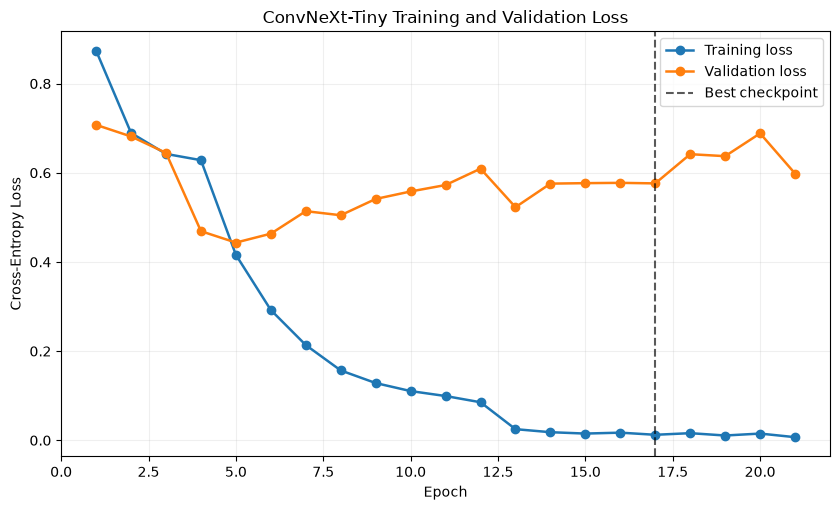

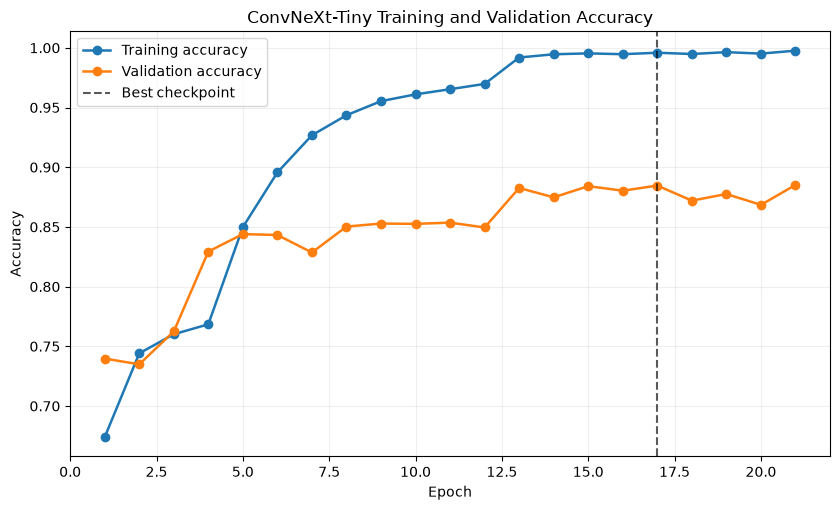

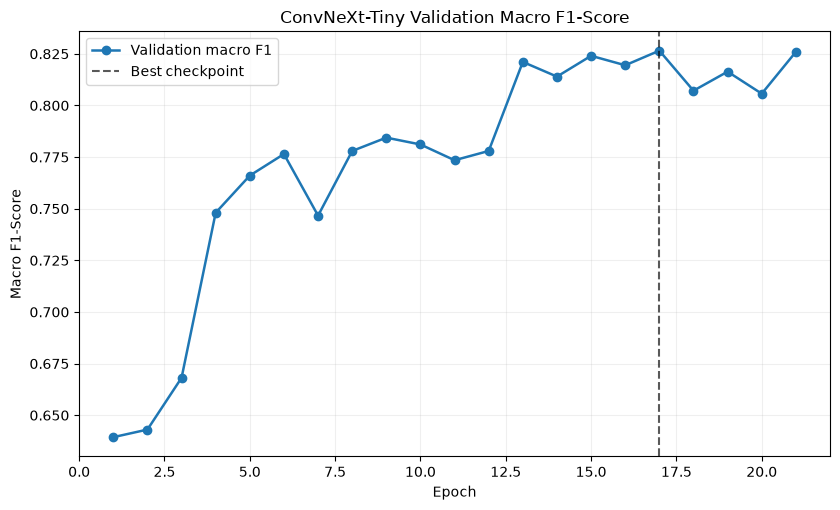

In [11]:
def save_curve(
    history_frame: pd.DataFrame,
    columns: list[str],
    labels: list[str],
    ylabel: str,
    title: str,
    output_path: Path,
) -> None:
    """Plot selected history columns and mark the checkpoint epoch."""
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    for column, label in zip(columns, labels):
        ax.plot(
            history_frame["epoch"],
            history_frame[column],
            marker="o",
            linewidth=1.8,
            label=label,
        )
    ax.axvline(
        best_epoch,
        color="black",
        linestyle="--",
        alpha=0.65,
        label="Best checkpoint",
    )
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.20)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


save_curve(
    training_history,
    ["train_loss", "val_loss"],
    ["Training loss", "Validation loss"],
    "Cross-Entropy Loss",
    "ConvNeXt-Tiny Training and Validation Loss",
    FIGURES_DIR / "05_convnext_tiny_loss_curve.png",
)
save_curve(
    training_history,
    ["train_accuracy", "val_accuracy"],
    ["Training accuracy", "Validation accuracy"],
    "Accuracy",
    "ConvNeXt-Tiny Training and Validation Accuracy",
    FIGURES_DIR / "05_convnext_tiny_accuracy_curve.png",
)
save_curve(
    training_history,
    ["val_macro_f1"],
    ["Validation macro F1"],
    "Macro F1-Score",
    "ConvNeXt-Tiny Validation Macro F1-Score",
    FIGURES_DIR / "05_convnext_tiny_macro_f1_curve.png",
)


## 12. Best-Checkpoint Validation Evaluation

The checkpoint selected by validation macro F1 is reloaded before all subsequent analysis. Overall and per-class results use schemas compatible with the preceding architecture baselines.


In [12]:
checkpoint = load_model_checkpoint(CHECKPOINT_PATH, model, DEVICE)

if checkpoint["class_mapping"] != CLASS_ID_TO_NAME:
    raise ValueError(
        "The checkpoint class mapping differs from the active manifest mapping."
    )
if checkpoint["architecture"] != "ConvNeXt-Tiny":
    raise ValueError("The checkpoint architecture metadata is inconsistent.")
if checkpoint["image_size"] != IMAGE_SIZE:
    raise ValueError("The checkpoint image size differs from the active pipeline.")

best_validation = evaluate_model(
    model,
    validation_loader,
    criterion,
    DEVICE,
    description="Best-checkpoint validation",
)
expected_validation_paths = manifests["validation"]["relative_path"].tolist()
if best_validation["relative_paths"] != expected_validation_paths:
    raise ValueError("Validation prediction order differs from the manifest order.")

validation_targets = best_validation["targets"]
validation_predictions = best_validation["predictions"]
validation_metric_values = {
    "accuracy": accuracy_score(validation_targets, validation_predictions),
    "balanced_accuracy": balanced_accuracy_score(
        validation_targets, validation_predictions
    ),
    "macro_f1": f1_score(
        validation_targets,
        validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "macro_precision": precision_score(
        validation_targets,
        validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "macro_recall": recall_score(
        validation_targets,
        validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        validation_targets,
        validation_predictions,
        average="weighted",
        zero_division=0,
    ),
}
validation_metrics_table = pd.DataFrame(
    {
        "metric": list(validation_metric_values),
        "value": list(validation_metric_values.values()),
    }
)
validation_metrics_table.to_csv(
    REPORTS_DIR / "05_convnext_tiny_validation_metrics.csv",
    index=False,
    encoding="utf-8",
)

class_ids = class_mapping_table["class_id"].to_numpy()
per_class_precision, per_class_recall, per_class_f1, per_class_support = (
    precision_recall_fscore_support(
        validation_targets,
        validation_predictions,
        labels=class_ids,
        zero_division=0,
    )
)
per_class_metrics = pd.DataFrame(
    {
        "class_id": class_ids,
        "class_name": [
            CLASS_ID_TO_NAME[int(class_id)] for class_id in class_ids
        ],
        "precision": per_class_precision,
        "recall": per_class_recall,
        "f1_score": per_class_f1,
        "support": per_class_support.astype(int),
    }
)
per_class_metrics.to_csv(
    REPORTS_DIR / "05_convnext_tiny_per_class_metrics.csv",
    index=False,
    encoding="utf-8",
)

print(
    f"Loaded best checkpoint from epoch {checkpoint['epoch']} "
    f"({checkpoint['stage']})."
)
display(validation_metrics_table.style.format({"value": "{:.4f}"}))
display(
    per_class_metrics.style.format(
        {
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1_score": "{:.4f}",
            "support": "{:,}",
        }
    )
)


Best-checkpoint validation:   0%|          | 0/248 [00:00<?, ?batch/s]

Loaded best checkpoint from epoch 17 (full_fine_tuning).


,metric,value
0,accuracy,0.8846
1,balanced_accuracy,0.8283
2,macro_f1,0.8265
3,macro_precision,0.8288
4,macro_recall,0.8283
5,weighted_f1,0.8850


,class_id,class_name,precision,recall,f1_score,support
0,0,Eczema,0.6146,0.8114,0.6994,228
1,1,Melanoma,1.0000,0.9958,0.9979,471
2,2,Atopic Dermatitis,0.6488,0.6374,0.6431,171
3,3,Basal Cell Carcinoma (BCC),0.9421,0.9819,0.9616,497
4,4,Melanocytic Nevi (NV),0.9856,0.9749,0.9802,"1,195"
5,5,Benign Keratosis-like Lesions (BKL),0.8922,0.8806,0.8864,310
6,6,Psoriasis / Lichen Planus / Related Diseases,0.7431,0.6438,0.6899,292
7,7,Seborrheic Keratoses / Other Benign Tumors,0.8785,0.7949,0.8346,273
8,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,0.7592,0.7592,0.7592,245
9,9,Warts / Molluscum / Other Viral Infections,0.8235,0.8029,0.8131,279


## 13. Confusion Matrices

The raw matrix reports image counts. Row normalization reports the recall distribution within each true class.


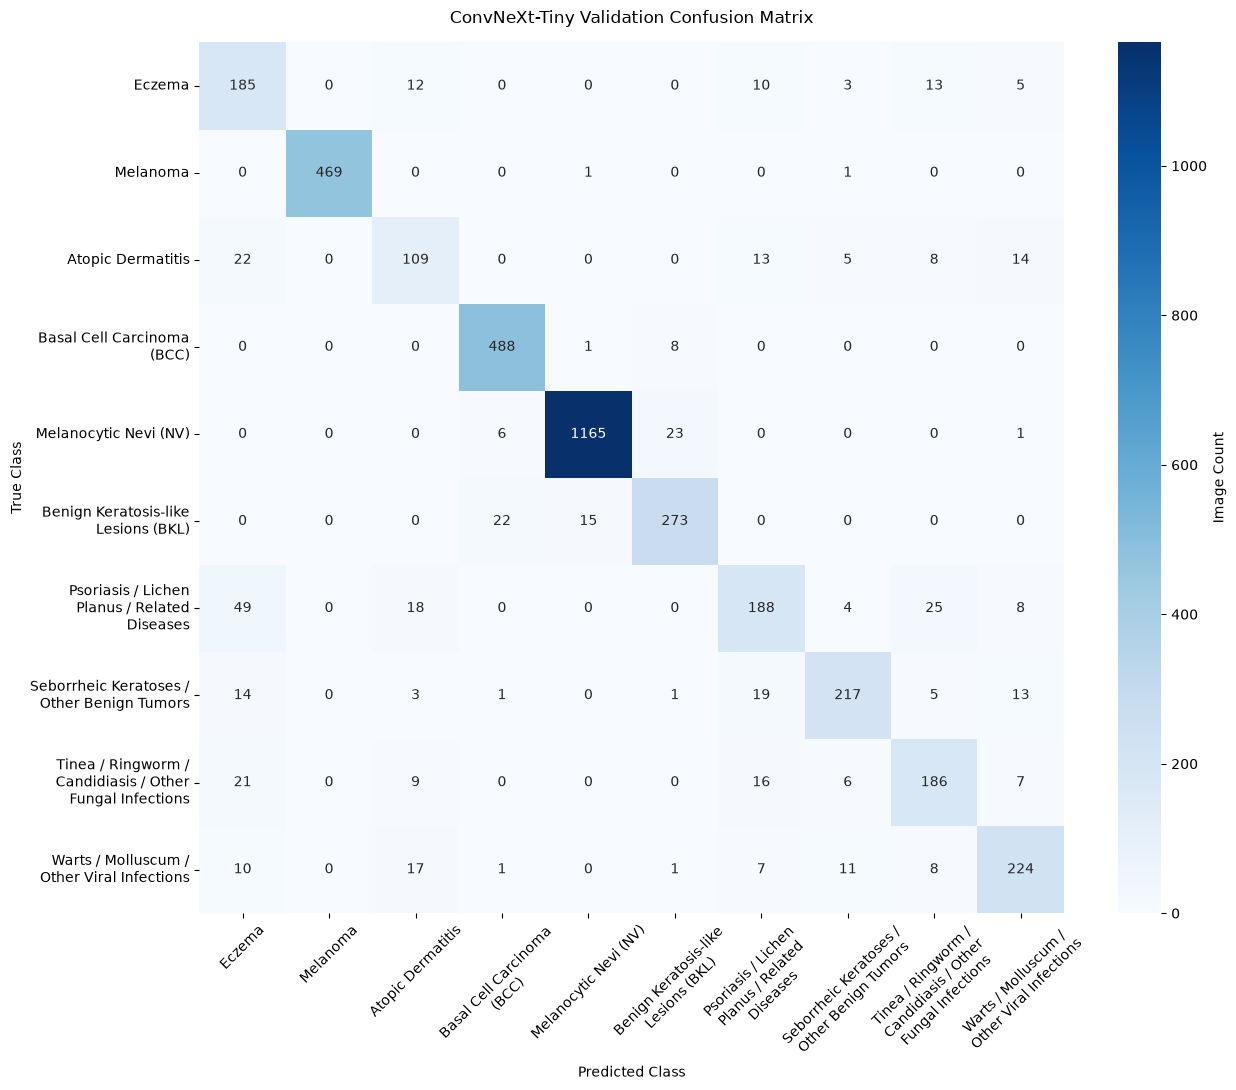

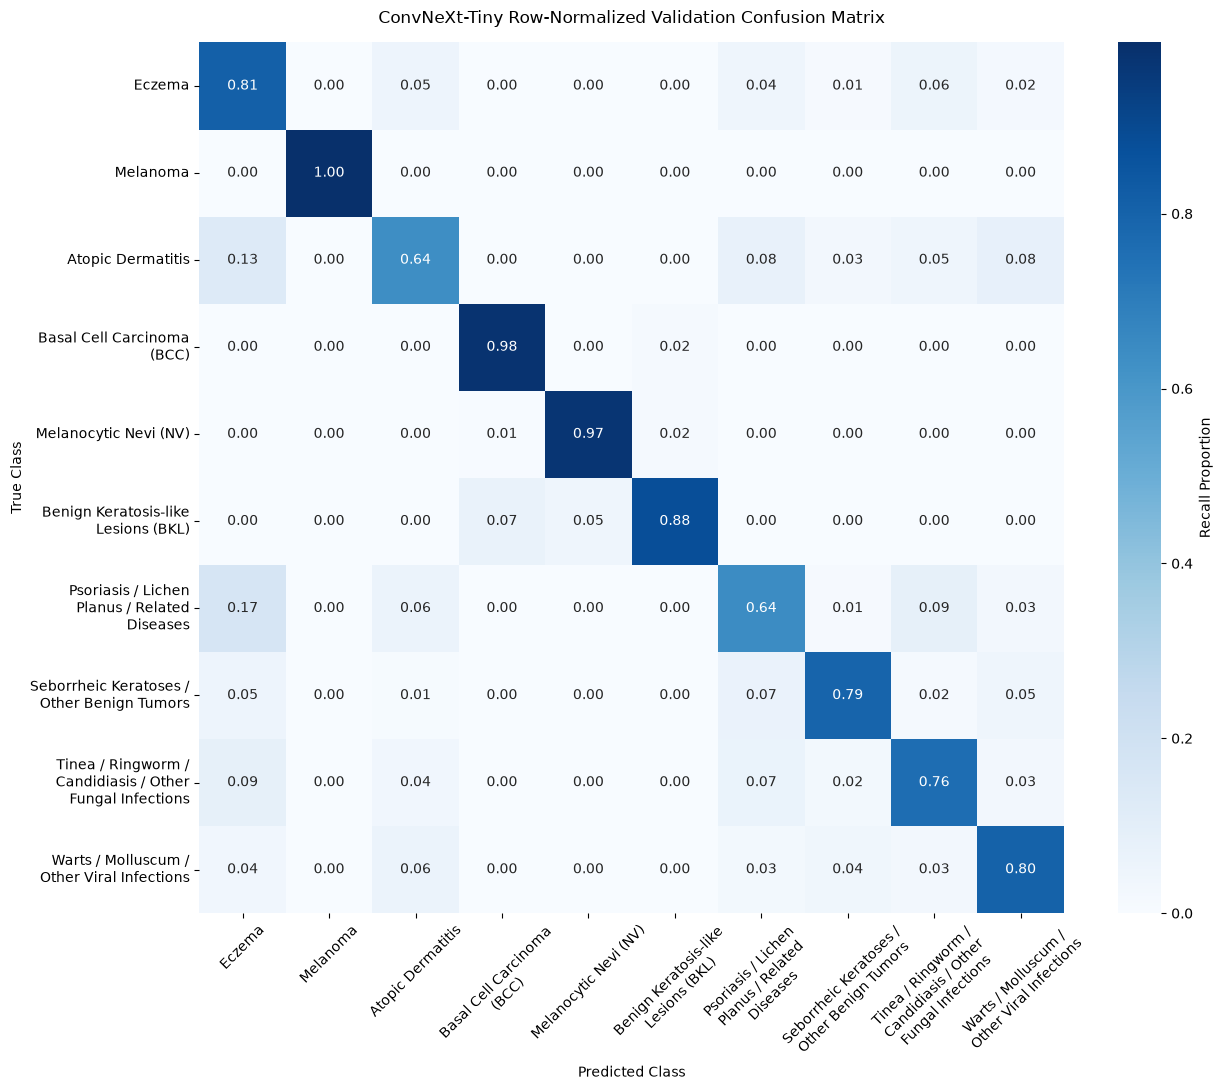

In [13]:
raw_confusion_matrix = confusion_matrix(
    validation_targets, validation_predictions, labels=class_ids
)
normalized_confusion_matrix = confusion_matrix(
    validation_targets,
    validation_predictions,
    labels=class_ids,
    normalize="true",
)
display_labels = [
    textwrap.fill(CLASS_ID_TO_NAME[int(class_id)], width=24)
    for class_id in class_ids
]


def plot_confusion_matrix(
    matrix,
    title: str,
    output_path: Path,
    value_format: str,
    colorbar_label: str,
) -> None:
    """Save a labeled validation confusion matrix."""
    fig, ax = plt.subplots(figsize=(13, 11))
    sns.heatmap(
        matrix,
        annot=True,
        fmt=value_format,
        cmap="Blues",
        xticklabels=display_labels,
        yticklabels=display_labels,
        cbar_kws={"label": colorbar_label},
        ax=ax,
    )
    ax.set_title(title, pad=14)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


plot_confusion_matrix(
    raw_confusion_matrix,
    "ConvNeXt-Tiny Validation Confusion Matrix",
    FIGURES_DIR / "05_convnext_tiny_confusion_matrix.png",
    "d",
    "Image Count",
)
plot_confusion_matrix(
    normalized_confusion_matrix,
    "ConvNeXt-Tiny Row-Normalized Validation Confusion Matrix",
    FIGURES_DIR / "05_convnext_tiny_confusion_matrix_normalized.png",
    ".2f",
    "Recall Proportion",
)


## 14. Error Analysis

Class-level extrema and directed confusion counts are reported descriptively. The fixed validation split and image labels do not support causal or medical explanations for these errors.


In [14]:
highest_recall_row = per_class_metrics.loc[per_class_metrics["recall"].idxmax()]
lowest_recall_row = per_class_metrics.loc[per_class_metrics["recall"].idxmin()]
highest_f1_row = per_class_metrics.loc[per_class_metrics["f1_score"].idxmax()]
lowest_f1_row = per_class_metrics.loc[per_class_metrics["f1_score"].idxmin()]

off_diagonal_confusions = raw_confusion_matrix.copy()
np.fill_diagonal(off_diagonal_confusions, 0)
confusion_records = []
for true_index, predicted_index in zip(
    *np.where(off_diagonal_confusions > 0)
):
    confusion_records.append(
        {
            "true_class": CLASS_ID_TO_NAME[int(class_ids[true_index])],
            "predicted_class": CLASS_ID_TO_NAME[
                int(class_ids[predicted_index])
            ],
            "image_count": int(
                off_diagonal_confusions[true_index, predicted_index]
            ),
        }
    )
frequent_confusions = pd.DataFrame(
    confusion_records,
    columns=["true_class", "predicted_class", "image_count"],
).sort_values(
    ["image_count", "true_class", "predicted_class"],
    ascending=[False, True, True],
    ignore_index=True,
)
if frequent_confusions.empty:
    most_common_confusion = {
        "true_class": "none",
        "predicted_class": "none",
        "image_count": 0,
    }
else:
    most_common_confusion = frequent_confusions.iloc[0]

print(
    f"Highest validation recall: {highest_recall_row['class_name']} "
    f"({highest_recall_row['recall']:.4f})"
)
print(
    f"Lowest validation recall: {lowest_recall_row['class_name']} "
    f"({lowest_recall_row['recall']:.4f})"
)
print(
    f"Highest validation F1: {highest_f1_row['class_name']} "
    f"({highest_f1_row['f1_score']:.4f})"
)
print(
    f"Lowest validation F1: {lowest_f1_row['class_name']} "
    f"({lowest_f1_row['f1_score']:.4f})"
)
print("Most frequent directed confusion pairs:")
display(frequent_confusions.head(10))


Highest validation recall: Melanoma (0.9958)
Lowest validation recall: Atopic Dermatitis (0.6374)
Highest validation F1: Melanoma (0.9979)
Lowest validation F1: Atopic Dermatitis (0.6431)
Most frequent directed confusion pairs:


,true_class,predicted_class,image_count
0,Psoriasis / Lichen Planus / Related Diseases,Eczema,49
1,Psoriasis / Lichen Planus / Related Diseases,Tinea / Ringworm / Candidiasis / Other Fungal ...,25
2,Melanocytic Nevi (NV),Benign Keratosis-like Lesions (BKL),23
3,Atopic Dermatitis,Eczema,22
4,Benign Keratosis-like Lesions (BKL),Basal Cell Carcinoma (BCC),22
5,Tinea / Ringworm / Candidiasis / Other Fungal ...,Eczema,21
6,Seborrheic Keratoses / Other Benign Tumors,Psoriasis / Lichen Planus / Related Diseases,19
7,Psoriasis / Lichen Planus / Related Diseases,Atopic Dermatitis,18
8,Warts / Molluscum / Other Viral Infections,Atopic Dermatitis,17
9,Tinea / Ringworm / Candidiasis / Other Fungal ...,Psoriasis / Lichen Planus / Related Diseases,16


## 15. Confidence Analysis and Saved Validation Predictions

Confidence is the maximum softmax probability and is not treated as calibrated clinical certainty. The complete validation prediction table is saved for later comparison, ensemble research, and poster preparation without retraining this model.


Average confidence for correct predictions: 0.9795
Average confidence for incorrect predictions: 0.8277
Saved validation predictions: C:\Projekt konferencyjny Turcja\skin-disease-classification\reports\predictions\05_convnext_tiny_validation_predictions.csv


,example_type,relative_path,true_class,predicted_class,confidence
0,High-confidence correct,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/t-eczema-hand-117.jpg,Eczema,Eczema,1.0000
1,High-confidence correct,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/t-eczema-hand-182.jpg,Eczema,Eczema,1.0000
2,High-confidence correct,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/v-03DermatitisLeg.jpg,Eczema,Eczema,1.0000
3,High-confidence correct,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/v-eczema-fingertips-10.jpg,Eczema,Eczema,1.0000
4,High-confidence incorrect,data/raw/skin-diseases-image-dataset/IMG_CLASSES/4. Basal Cell Carcinoma (BCC) 3323/ISIC_0071742.jpg,Basal Cell Carcinoma (BCC),Benign Keratosis-like Lesions (BKL),1.0000
5,High-confidence incorrect,data/raw/skin-diseases-image-dataset/IMG_CLASSES/5. Melanocytic Nevi (NV) - 7970/ISIC_0026569.jpg,Melanocytic Nevi (NV),Basal Cell Carcinoma (BCC),1.0000
6,High-confidence incorrect,data/raw/skin-diseases-image-dataset/IMG_CLASSES/10. Warts Molluscum and other Viral Infections - 2103/3_56.jpg,Warts / Molluscum / Other Viral Infections,Basal Cell Carcinoma (BCC),1.0000
7,High-confidence incorrect,data/raw/skin-diseases-image-dataset/IMG_CLASSES/6. Benign Keratosis-like Lesions (BKL) 2624/ISIC_0056149.jpg,Benign Keratosis-like Lesions (BKL),Basal Cell Carcinoma (BCC),1.0000


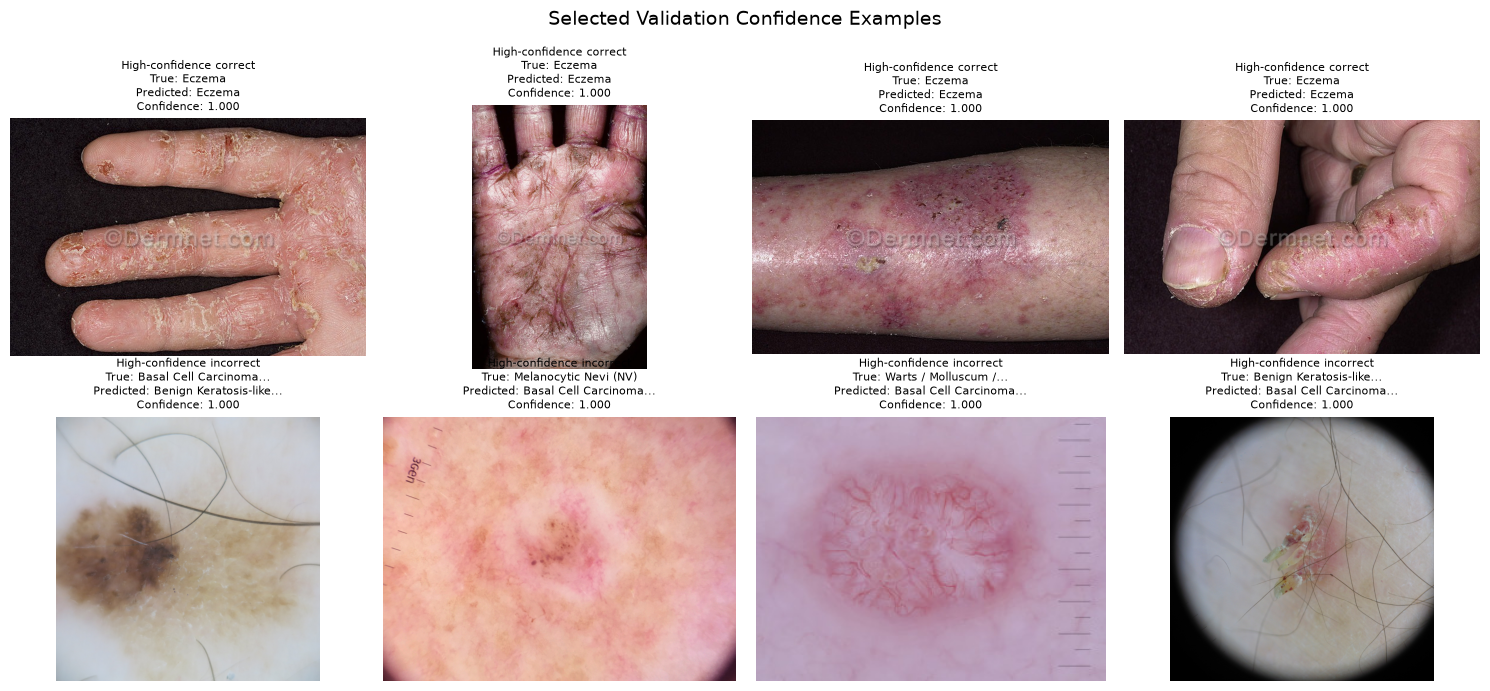

In [15]:
validation_predictions_table = pd.DataFrame(
    {
        "relative_path": best_validation["relative_paths"],
        "true_class_id": validation_targets,
        "true_class": [
            CLASS_ID_TO_NAME[int(class_id)] for class_id in validation_targets
        ],
        "predicted_class_id": validation_predictions,
        "predicted_class": [
            CLASS_ID_TO_NAME[int(class_id)]
            for class_id in validation_predictions
        ],
        "confidence": best_validation["confidences"],
        "correct": validation_targets == validation_predictions,
    }
)
for probability_index, class_id in enumerate(class_ids):
    validation_predictions_table[f"prob_class_{int(class_id)}"] = (
        best_validation["probabilities"][:, probability_index]
    )

PREDICTIONS_PATH = (
    PREDICTIONS_DIR / "05_convnext_tiny_validation_predictions.csv"
)
validation_predictions_table.to_csv(
    PREDICTIONS_PATH, index=False, encoding="utf-8"
)

correct_confidence = validation_predictions_table.loc[
    validation_predictions_table["correct"], "confidence"
].mean()
incorrect_confidence = validation_predictions_table.loc[
    ~validation_predictions_table["correct"], "confidence"
].mean()

print(f"Average confidence for correct predictions: {correct_confidence:.4f}")
print(f"Average confidence for incorrect predictions: {incorrect_confidence:.4f}")
print(f"Saved validation predictions: {PREDICTIONS_PATH}")

confidence_examples = pd.concat(
    [
        validation_predictions_table.loc[
            validation_predictions_table["correct"]
        ]
        .nlargest(4, "confidence")
        .assign(example_type="High-confidence correct"),
        validation_predictions_table.loc[
            ~validation_predictions_table["correct"]
        ]
        .nlargest(4, "confidence")
        .assign(example_type="High-confidence incorrect"),
    ],
    ignore_index=True,
)
display(
    confidence_examples[
        [
            "example_type",
            "relative_path",
            "true_class",
            "predicted_class",
            "confidence",
        ]
    ].style.format({"confidence": "{:.4f}"})
)

fig, axes = plt.subplots(2, 4, figsize=(15, 7), squeeze=False)
for axis, (_, row) in zip(axes.flat, confidence_examples.iterrows()):
    with Image.open(PROJECT_ROOT / row["relative_path"]) as image:
        image_for_display = ImageOps.exif_transpose(image).convert("RGB")
        axis.imshow(image_for_display)
    axis.set_title(
        f"{row['example_type']}\n"
        f"True: {textwrap.shorten(row['true_class'], 24, placeholder='...')}\n"
        f"Predicted: "
        f"{textwrap.shorten(row['predicted_class'], 24, placeholder='...')}\n"
        f"Confidence: {row['confidence']:.3f}",
        fontsize=8,
    )
    axis.axis("off")
for axis in axes.flat[len(confidence_examples):]:
    axis.axis("off")
fig.suptitle("Selected Validation Confidence Examples", fontsize=14)
fig.tight_layout()
plt.show()


## 16. Overfitting and Generalization Analysis

The training-validation accuracy gap is evaluated at the checkpoint selected by macro F1. The per-class F1 range and rank correlation with validation support provide descriptive indicators of performance inequality; neither establishes causation.


In [16]:
selected_history = training_history.loc[
    training_history["epoch"] == checkpoint["epoch"]
]
if len(selected_history) != 1:
    raise ValueError(
        "The selected checkpoint epoch is not unique in the training history."
    )

best_history_row = selected_history.iloc[0]
first_history_row = training_history.iloc[0]
last_history_row = training_history.iloc[-1]
minimum_validation_loss_row = training_history.loc[
    training_history["val_loss"].idxmin()
]

training_validation_gap = (
    best_history_row["train_accuracy"] - validation_metric_values["accuracy"]
)
per_class_f1_range = (
    per_class_metrics["f1_score"].max()
    - per_class_metrics["f1_score"].min()
)
support_f1_spearman = per_class_metrics["support"].corr(
    per_class_metrics["f1_score"], method="spearman"
)

generalization_indicators = pd.DataFrame(
    {
        "indicator": [
            "Training-validation accuracy gap at selected checkpoint",
            "Per-class F1 range",
            "Spearman correlation: validation support vs. F1",
        ],
        "value": [
            training_validation_gap,
            per_class_f1_range,
            support_f1_spearman,
        ],
    }
)
display(generalization_indicators.style.format({"value": "{:.4f}"}))

if training_validation_gap > 0.10:
    fit_interpretation = (
        "The selected checkpoint has a notable positive accuracy gap, which is "
        "compatible with overfitting pressure."
    )
elif training_validation_gap > 0.03:
    fit_interpretation = (
        "The selected checkpoint has a modest positive accuracy gap, indicating "
        "some overfitting pressure."
    )
else:
    fit_interpretation = (
        "The selected checkpoint does not show a large positive accuracy gap."
    )

if pd.isna(support_f1_spearman):
    support_interpretation = (
        "The support-F1 rank correlation is undefined for the observed values."
    )
elif abs(support_f1_spearman) <= 0.30:
    support_interpretation = (
        "The rank association between validation support and F1 is weak."
    )
elif support_f1_spearman > 0:
    support_interpretation = (
        "Validation support and F1 show a positive rank association."
    )
else:
    support_interpretation = (
        "Validation support and F1 show a negative rank association."
    )

interpretation_markdown = f"""
At the selected epoch, training accuracy was {best_history_row['train_accuracy']:.4f} and validation accuracy was {validation_metric_values['accuracy']:.4f}, producing a gap of {training_validation_gap:+.4f}. {fit_interpretation}

Per-class F1 spans {per_class_f1_range:.4f}; the Spearman correlation between validation support and F1 is {support_f1_spearman:.4f}. {support_interpretation} These statistics describe one fixed validation subset and do not imply that class frequency causes the observed differences.

Validation loss reached its minimum of {minimum_validation_loss_row['val_loss']:.4f} at epoch {int(minimum_validation_loss_row['epoch'])}. The final recorded validation loss was {last_history_row['val_loss']:.4f}. Validation selection, softmax confidence, and the present split do not establish external generalization or clinical diagnostic reliability.
"""
display(Markdown(interpretation_markdown))


,indicator,value
0,Training-validation accuracy gap at selected checkpoint,0.1113
1,Per-class F1 range,0.3548
2,Spearman correlation: validation support vs. F1,0.8303



At the selected epoch, training accuracy was 0.9959 and validation accuracy was 0.8846, producing a gap of +0.1113. The selected checkpoint has a notable positive accuracy gap, which is compatible with overfitting pressure.

Per-class F1 spans 0.3548; the Spearman correlation between validation support and F1 is 0.8303. Validation support and F1 show a positive rank association. These statistics describe one fixed validation subset and do not imply that class frequency causes the observed differences.

Validation loss reached its minimum of 0.4434 at epoch 5. The final recorded validation loss was 0.5983. Validation selection, softmax confidence, and the present split do not establish external generalization or clinical diagnostic reliability.


## 17. Three-Model Architecture Comparison

ResNet50 and EfficientNetV2-S results are loaded from their saved reports. No previous metric is hardcoded. The comparison covers the same six aggregate validation measures, while the figure focuses on accuracy, balanced accuracy, and macro F1.


,architecture,accuracy,balanced_accuracy,macro_f1,macro_precision,macro_recall,weighted_f1
0,ResNet50,0.8533,0.7885,0.7869,0.7869,0.7885,0.8533
1,EfficientNetV2-S,0.8892,0.8327,0.8319,0.8349,0.8327,0.8902
2,ConvNeXt-Tiny,0.8846,0.8283,0.8265,0.8288,0.8283,0.8850


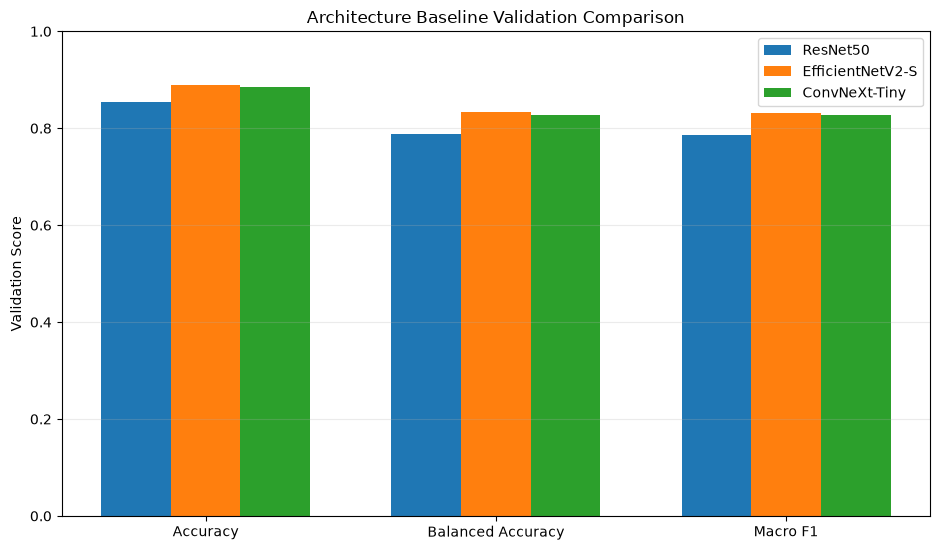

,architecture,selected_epoch,training_validation_accuracy_gap
0,ResNet50,19,+0.1294
1,EfficientNetV2-S,20,+0.1044
2,ConvNeXt-Tiny,17,+0.1113


In [17]:
BASELINE_REPORTS = {
    "ResNet50": {
        "metrics": REPORTS_DIR / "03_resnet50_validation_metrics.csv",
        "per_class": REPORTS_DIR / "03_resnet50_per_class_metrics.csv",
        "history": REPORTS_DIR / "03_resnet50_training_history.csv",
    },
    "EfficientNetV2-S": {
        "metrics": REPORTS_DIR / "04_efficientnetv2_validation_metrics.csv",
        "per_class": REPORTS_DIR / "04_efficientnetv2_per_class_metrics.csv",
        "history": REPORTS_DIR / "04_efficientnetv2_training_history.csv",
    },
    "ConvNeXt-Tiny": {
        "metrics": REPORTS_DIR / "05_convnext_tiny_validation_metrics.csv",
        "per_class": REPORTS_DIR / "05_convnext_tiny_per_class_metrics.csv",
        "history": REPORTS_DIR / "05_convnext_tiny_training_history.csv",
    },
}
missing_baseline_reports = [
    path
    for report_group in BASELINE_REPORTS.values()
    for path in report_group.values()
    if not path.is_file()
]
if missing_baseline_reports:
    missing_text = "\n".join(f"  - {path}" for path in missing_baseline_reports)
    raise FileNotFoundError(
        "Architecture comparison reports are missing:\n" f"{missing_text}"
    )

COMPARISON_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "macro_precision",
    "macro_recall",
    "weighted_f1",
]


def load_metric_report(path: Path) -> pd.Series:
    """Load and validate a metric,value report."""
    report = pd.read_csv(path)
    if list(report.columns) != ["metric", "value"]:
        raise ValueError(f"Unexpected overall metric schema in {path.name}.")
    if report["metric"].duplicated().any():
        raise ValueError(f"Duplicate metric names exist in {path.name}.")
    values = report.set_index("metric")["value"].astype(float)
    missing_metrics = [
        metric for metric in COMPARISON_METRICS if metric not in values.index
    ]
    if missing_metrics:
        raise ValueError(
            f"{path.name} is missing comparison metrics: {missing_metrics}"
        )
    return values


architecture_metric_series = {
    architecture: load_metric_report(paths["metrics"])
    for architecture, paths in BASELINE_REPORTS.items()
}
architecture_comparison = pd.DataFrame(
    [
        {
            "architecture": architecture,
            **{
                metric: metric_values[metric]
                for metric in COMPARISON_METRICS
            },
        }
        for architecture, metric_values in architecture_metric_series.items()
    ]
)
architecture_comparison.to_csv(
    REPORTS_DIR / "05_architecture_baseline_comparison.csv",
    index=False,
    encoding="utf-8",
)
display(
    architecture_comparison.style.format(
        {metric: "{:.4f}" for metric in COMPARISON_METRICS}
    )
)

main_metrics = ["accuracy", "balanced_accuracy", "macro_f1"]
main_metric_labels = ["Accuracy", "Balanced Accuracy", "Macro F1"]
x_positions = np.arange(len(main_metrics))
bar_width = 0.24

fig, ax = plt.subplots(figsize=(9.5, 5.6))
for model_index, row in architecture_comparison.iterrows():
    offset = (model_index - 1) * bar_width
    ax.bar(
        x_positions + offset,
        row[main_metrics].astype(float),
        width=bar_width,
        label=row["architecture"],
    )
ax.set_xticks(x_positions, main_metric_labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Validation Score")
ax.set_title("Architecture Baseline Validation Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "05_architecture_baseline_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

generalization_gap_records = []
for architecture, paths in BASELINE_REPORTS.items():
    history_report = pd.read_csv(paths["history"])
    required_history_columns = {
        "epoch",
        "train_accuracy",
        "val_accuracy",
        "val_macro_f1",
    }
    missing_columns = required_history_columns - set(history_report.columns)
    if missing_columns:
        raise ValueError(
            f"{paths['history'].name} is missing columns: "
            f"{sorted(missing_columns)}"
        )
    selected_row = history_report.loc[history_report["val_macro_f1"].idxmax()]
    report_accuracy = architecture_metric_series[architecture]["accuracy"]
    generalization_gap_records.append(
        {
            "architecture": architecture,
            "selected_epoch": int(selected_row["epoch"]),
            "training_validation_accuracy_gap": (
                float(selected_row["train_accuracy"]) - report_accuracy
            ),
        }
    )
generalization_gap_comparison = pd.DataFrame(generalization_gap_records)
display(
    generalization_gap_comparison.style.format(
        {"training_validation_accuracy_gap": "{:+.4f}"}
    )
)

efficientnet_gap = generalization_gap_comparison.set_index("architecture").loc[
    "EfficientNetV2-S", "training_validation_accuracy_gap"
]
convnext_gap_difference = training_validation_gap - efficientnet_gap


## 18. Per-Class Architecture Comparison

Per-class F1 is joined by both class identifier and class name. The comparison also examines the three weakest EfficientNetV2-S classes to determine whether ConvNeXt-Tiny improves the previously weaker class-level results. Small differences are retained numerically but are not treated as proof of meaningful superiority.


In [18]:
EXPECTED_PER_CLASS_COLUMNS = {
    "class_id",
    "class_name",
    "precision",
    "recall",
    "f1_score",
    "support",
}


def load_per_class_report(path: Path, f1_column_name: str) -> pd.DataFrame:
    """Load a per-class report and retain validated identifiers and F1."""
    report = pd.read_csv(path)
    if set(report.columns) != EXPECTED_PER_CLASS_COLUMNS:
        raise ValueError(f"Unexpected per-class metric schema in {path.name}.")
    if report[["class_id", "class_name"]].duplicated().any():
        raise ValueError(f"Duplicate class rows exist in {path.name}.")
    return report[["class_id", "class_name", "f1_score"]].rename(
        columns={"f1_score": f1_column_name}
    )


per_class_architecture_comparison = load_per_class_report(
    BASELINE_REPORTS["ResNet50"]["per_class"], "resnet50_f1"
)
per_class_architecture_comparison = per_class_architecture_comparison.merge(
    load_per_class_report(
        BASELINE_REPORTS["EfficientNetV2-S"]["per_class"],
        "efficientnetv2_s_f1",
    ),
    on=["class_id", "class_name"],
    how="inner",
    validate="one_to_one",
)
per_class_architecture_comparison = per_class_architecture_comparison.merge(
    load_per_class_report(
        BASELINE_REPORTS["ConvNeXt-Tiny"]["per_class"],
        "convnext_tiny_f1",
    ),
    on=["class_id", "class_name"],
    how="inner",
    validate="one_to_one",
)
if len(per_class_architecture_comparison) != NUM_CLASSES:
    raise ValueError(
        "The architecture reports do not share the full active class mapping."
    )

f1_columns = ["resnet50_f1", "efficientnetv2_s_f1", "convnext_tiny_f1"]
f1_to_architecture = {
    "resnet50_f1": "ResNet50",
    "efficientnetv2_s_f1": "EfficientNetV2-S",
    "convnext_tiny_f1": "ConvNeXt-Tiny",
}
per_class_architecture_comparison["best_architecture"] = (
    per_class_architecture_comparison[f1_columns]
    .idxmax(axis=1)
    .map(f1_to_architecture)
)
per_class_architecture_comparison[
    "convnext_vs_efficientnetv2_s_f1"
] = (
    per_class_architecture_comparison["convnext_tiny_f1"]
    - per_class_architecture_comparison["efficientnetv2_s_f1"]
)
per_class_architecture_comparison.to_csv(
    REPORTS_DIR / "05_architecture_per_class_f1.csv",
    index=False,
    encoding="utf-8",
)

largest_convnext_improvement = per_class_architecture_comparison.loc[
    per_class_architecture_comparison[
        "convnext_vs_efficientnetv2_s_f1"
    ].idxmax()
]
largest_convnext_decrease = per_class_architecture_comparison.loc[
    per_class_architecture_comparison[
        "convnext_vs_efficientnetv2_s_f1"
    ].idxmin()
]
efficientnet_weakest_classes = (
    per_class_architecture_comparison.nsmallest(3, "efficientnetv2_s_f1")
    .sort_values("efficientnetv2_s_f1")
    .reset_index(drop=True)
)

display(
    per_class_architecture_comparison.style.format(
        {column: "{:.4f}" for column in f1_columns}
        | {"convnext_vs_efficientnetv2_s_f1": "{:+.4f}"}
    )
)
print("Three weakest EfficientNetV2-S classes and their ConvNeXt-Tiny changes:")
display(
    efficientnet_weakest_classes[
        [
            "class_name",
            "efficientnetv2_s_f1",
            "convnext_tiny_f1",
            "convnext_vs_efficientnetv2_s_f1",
        ]
    ].style.format(
        {
            "efficientnetv2_s_f1": "{:.4f}",
            "convnext_tiny_f1": "{:.4f}",
            "convnext_vs_efficientnetv2_s_f1": "{:+.4f}",
        }
    )
)
print(
    "Largest ConvNeXt-Tiny minus EfficientNetV2-S per-class F1 difference: "
    f"{largest_convnext_improvement['class_name']} "
    f"({largest_convnext_improvement['convnext_vs_efficientnetv2_s_f1']:+.4f})"
)
print(
    "Largest ConvNeXt-Tiny decrease relative to EfficientNetV2-S: "
    f"{largest_convnext_decrease['class_name']} "
    f"({largest_convnext_decrease['convnext_vs_efficientnetv2_s_f1']:+.4f})"
)


,class_id,class_name,resnet50_f1,efficientnetv2_s_f1,convnext_tiny_f1,best_architecture,convnext_vs_efficientnetv2_s_f1
0,0,Eczema,0.7009,0.7078,0.6994,EfficientNetV2-S,-0.0083
1,1,Melanoma,0.9882,0.9947,0.9979,ConvNeXt-Tiny,+0.0032
2,2,Atopic Dermatitis,0.6331,0.6188,0.6431,ConvNeXt-Tiny,+0.0243
3,3,Basal Cell Carcinoma (BCC),0.9388,0.9622,0.9616,EfficientNetV2-S,-0.0006
4,4,Melanocytic Nevi (NV),0.9694,0.9845,0.9802,EfficientNetV2-S,-0.0043
5,5,Benign Keratosis-like Lesions (BKL),0.8357,0.8977,0.8864,EfficientNetV2-S,-0.0113
6,6,Psoriasis / Lichen Planus / Related Diseases,0.6542,0.7379,0.6899,EfficientNetV2-S,-0.0480
7,7,Seborrheic Keratoses / Other Benign Tumors,0.7700,0.8405,0.8346,EfficientNetV2-S,-0.0059
8,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,0.6851,0.7880,0.7592,EfficientNetV2-S,-0.0288
9,9,Warts / Molluscum / Other Viral Infections,0.6932,0.7870,0.8131,ConvNeXt-Tiny,+0.0261


Three weakest EfficientNetV2-S classes and their ConvNeXt-Tiny changes:


,class_name,efficientnetv2_s_f1,convnext_tiny_f1,convnext_vs_efficientnetv2_s_f1
0,Atopic Dermatitis,0.6188,0.6431,+0.0243
1,Eczema,0.7078,0.6994,-0.0083
2,Psoriasis / Lichen Planus / Related Diseases,0.7379,0.6899,-0.0480


Largest ConvNeXt-Tiny minus EfficientNetV2-S per-class F1 difference: Warts / Molluscum / Other Viral Infections (+0.0261)
Largest ConvNeXt-Tiny decrease relative to EfficientNetV2-S: Psoriasis / Lichen Planus / Related Diseases (-0.0480)


## 19. Test Set Policy

The test manifest was checked only for structure, class mapping, group separation, row count, and referenced files. It was not used to construct a dataset or loader, select a checkpoint, tune a decision, or calculate any predictive metric.


In [19]:
TEST_SET_PREDICTIONS_GENERATED = False
print(f"Test-set predictions generated: {TEST_SET_PREDICTIONS_GENERATED}")


Test-set predictions generated: False


## ConvNeXt-Tiny Baseline Summary

The following values are generated from the selected checkpoint and its saved validation outputs.


In [20]:
most_common_confusion_text = (
    f"true {most_common_confusion['true_class']} predicted as "
    f"{most_common_confusion['predicted_class']} "
    f"({int(most_common_confusion['image_count'])} images)"
)
summary_markdown = f"""
- **Best checkpoint epoch:** {checkpoint['epoch']} ({checkpoint['stage'].replace('_', ' ')})
- **Validation accuracy:** {validation_metric_values['accuracy']:.4f}
- **Validation balanced accuracy:** {validation_metric_values['balanced_accuracy']:.4f}
- **Validation macro F1:** {validation_metric_values['macro_f1']:.4f}
- **Validation macro precision:** {validation_metric_values['macro_precision']:.4f}
- **Validation macro recall:** {validation_metric_values['macro_recall']:.4f}
- **Strongest class by F1:** {highest_f1_row['class_name']} ({highest_f1_row['f1_score']:.4f})
- **Weakest class by F1:** {lowest_f1_row['class_name']} ({lowest_f1_row['f1_score']:.4f})
- **Most common directed confusion:** {most_common_confusion_text}
- **Training-validation accuracy gap:** {training_validation_gap:+.4f}
"""
display(Markdown(summary_markdown))



- **Best checkpoint epoch:** 17 (full fine tuning)
- **Validation accuracy:** 0.8846
- **Validation balanced accuracy:** 0.8283
- **Validation macro F1:** 0.8265
- **Validation macro precision:** 0.8288
- **Validation macro recall:** 0.8283
- **Strongest class by F1:** Melanoma (0.9979)
- **Weakest class by F1:** Atopic Dermatitis (0.6431)
- **Most common directed confusion:** true Psoriasis / Lichen Planus / Related Diseases predicted as Eczema (49 images)
- **Training-validation accuracy gap:** +0.1113


### Architecture Comparison

This is validation-based architecture selection, not final test performance. Differences are descriptive results from one fixed validation split and should not be interpreted as statistical or clinical evidence.


In [21]:
architecture_rankings = {}
comparison_lines = []
for metric in main_metrics:
    ranking = architecture_comparison.sort_values(metric, ascending=False)
    best_model = ranking.iloc[0]["architecture"]
    second_model = ranking.iloc[1]["architecture"]
    best_value = float(ranking.iloc[0][metric])
    second_value = float(ranking.iloc[1][metric])
    architecture_rankings[metric] = best_model
    comparison_lines.append(
        f"- **{metric.replace('_', ' ').title()}:** {best_model} "
        f"({best_value:.4f}), ahead of {second_model} by "
        f"{best_value - second_value:.4f}."
    )

architecture_win_counts = pd.Series(architecture_rankings).value_counts()
maximum_wins = architecture_win_counts.max()
selection_candidates = architecture_win_counts[
    architecture_win_counts == maximum_wins
].index.tolist()
if len(selection_candidates) > 1:
    comparison_means = architecture_comparison.set_index("architecture")[
        main_metrics
    ].mean(axis=1)
    validation_selection_candidate = comparison_means.loc[
        selection_candidates
    ].idxmax()
else:
    validation_selection_candidate = selection_candidates[0]

convnext_vs_efficientnet = {
    metric: (
        architecture_metric_series["ConvNeXt-Tiny"][metric]
        - architecture_metric_series["EfficientNetV2-S"][metric]
    )
    for metric in main_metrics
}
weak_class_improvement_count = int(
    (
        efficientnet_weakest_classes[
            "convnext_vs_efficientnetv2_s_f1"
        ]
        > 0
    ).sum()
)
if convnext_gap_difference > 0:
    gap_text = (
        "ConvNeXt-Tiny's training-validation accuracy gap is larger than "
        f"EfficientNetV2-S's by {convnext_gap_difference:.4f}."
    )
elif convnext_gap_difference < 0:
    gap_text = (
        "ConvNeXt-Tiny's training-validation accuracy gap is smaller than "
        f"EfficientNetV2-S's by {abs(convnext_gap_difference):.4f}."
    )
else:
    gap_text = (
        "ConvNeXt-Tiny and EfficientNetV2-S have equal "
        "training-validation accuracy gaps."
    )

architecture_summary_markdown = f"""
{chr(10).join(comparison_lines)}

Relative to EfficientNetV2-S, ConvNeXt-Tiny changes validation accuracy by {convnext_vs_efficientnet['accuracy']:+.4f}, balanced accuracy by {convnext_vs_efficientnet['balanced_accuracy']:+.4f}, and macro F1 by {convnext_vs_efficientnet['macro_f1']:+.4f}. It improves F1 for {weak_class_improvement_count} of the three weakest EfficientNetV2-S classes. {gap_text}

On the three primary validation metrics, **{validation_selection_candidate}** is the current candidate to proceed to later optimization. This choice remains provisional until the additional architecture baseline is evaluated and does not represent final test-set selection.
"""
display(Markdown(architecture_summary_markdown))



- **Accuracy:** EfficientNetV2-S (0.8892), ahead of ConvNeXt-Tiny by 0.0045.
- **Balanced Accuracy:** EfficientNetV2-S (0.8327), ahead of ConvNeXt-Tiny by 0.0045.
- **Macro F1:** EfficientNetV2-S (0.8319), ahead of ConvNeXt-Tiny by 0.0054.

Relative to EfficientNetV2-S, ConvNeXt-Tiny changes validation accuracy by -0.0045, balanced accuracy by -0.0045, and macro F1 by -0.0054. It improves F1 for 1 of the three weakest EfficientNetV2-S classes. ConvNeXt-Tiny's training-validation accuracy gap is larger than EfficientNetV2-S's by 0.0068.

On the three primary validation metrics, **EfficientNetV2-S** is the current candidate to proceed to later optimization. This choice remains provisional until the additional architecture baseline is evaluated and does not represent final test-set selection.


### Outputs for Final Analysis and Poster Preparation

This notebook saves standardized overall validation metrics, per-class metrics, training history, raw and normalized confusion matrices, and complete validation predictions. The CSV schemas are aligned with the preceding baselines so that later analysis can generate model-comparison and per-class figures without rerunning this training.

These baseline outputs will later be combined with the optimized or final model results. Final poster graphics are intentionally deferred; they should compare selected final models rather than only the initial architecture baselines. Expected later outputs include overall Accuracy/Balanced Accuracy/Macro F1 comparison, per-class F1 comparison, the selected final model's normalized confusion matrix and learning curves, and optional Grad-CAM examples from that selected model.


### Next Step

One additional fundamentally different pretrained architecture should be evaluated before architecture selection is finalized. The next candidate will use a transformer or self-supervised vision approach. Its training is outside the scope of this notebook.


## Reproducibility Summary

The recorded configuration and execution-specific software and hardware information provide the minimum context required to repeat this baseline.


In [22]:
configuration_summary = pd.DataFrame(
    {
        "Configuration Item": [
            "Random seed",
            "Architecture",
            "Pretrained weights",
            "Input size",
            "Batch size",
            "Optimizer",
            "Warm-up learning rate",
            "Fine-tuning learning rate",
            "Weight decay",
            "Warm-up epochs",
            "Maximum fine-tuning epochs",
            "Early stopping patience",
            "Checkpoint criterion",
            "PyTorch version",
            "torchvision version",
            "CUDA version",
            "GPU name",
        ],
        "Value": [
            RANDOM_SEED,
            "ConvNeXt-Tiny",
            PRETRAINED_WEIGHTS.name,
            f"{IMAGE_SIZE} x {IMAGE_SIZE}",
            BATCH_SIZE,
            "AdamW",
            WARMUP_LEARNING_RATE,
            FINE_TUNE_LEARNING_RATE,
            WEIGHT_DECAY,
            WARMUP_EPOCHS,
            FINE_TUNE_MAX_EPOCHS,
            EARLY_STOPPING_PATIENCE,
            CHECKPOINT_CRITERION,
            torch.__version__,
            torchvision.__version__,
            torch.version.cuda,
            GPU_NAME,
        ],
    }
)
display(configuration_summary)
print(f"Completed epochs: {len(training_history)}")
print(
    "Best checkpoint path: "
    f"{CHECKPOINT_PATH.relative_to(PROJECT_ROOT).as_posix()}"
)
print("Test-set predictions generated: False")


,Configuration Item,Value
0,Random seed,42
1,Architecture,ConvNeXt-Tiny
2,Pretrained weights,IMAGENET1K_V1
3,Input size,224 x 224
4,Batch size,16
5,Optimizer,AdamW
6,Warm-up learning rate,0.001
7,Fine-tuning learning rate,0.0001
8,Weight decay,0.0001
9,Warm-up epochs,3


Completed epochs: 21
Best checkpoint path: models/convnext_tiny_baseline_best.pth
Test-set predictions generated: False
